# Problem ID: Category11_Problem02 — Rain-Slick Campus Courier

**_Solution Key_**

### 1. Problem Scenario
A campus delivery robot moves between buildings during rain. Wet tiles introduce stochastic sideways slips, so the same action can produce different next states.

The environment is a stochastic Markov Decision Process. From a normal tile, the intended movement occurs with probability **0.75**. The two perpendicular movements each occur with probability **0.12**. If the agent is currently on a specially slippery tile, the intended movement probability becomes **0.60**, with the remaining probability split equally between the two perpendicular directions. The realized transition is sampled at runtime.

### 2. System Specifications
- **State Space ($S$):** 25 discrete grid cells, represented by state index `row * 5 + col`.
- **Action Space ($A$):** `0: UP`, `1: DOWN`, `2: LEFT`, `3: RIGHT`.
- **Start State:** `(4, 0)`.
- **Goal State:** `(0, 4)`.
- **Hazard States:** `(2, 2)`. Entering a hazard terminates the episode.
- **Obstacle States:** `(3, 1), (3, 2), (1, 3)`. An attempted move into an obstacle or outside the grid leaves the agent in the current state.
- **Normal slip model:** intended action = `0.75`; each perpendicular action = `0.12`.
- **Special slippery-tile model:** intended action = `0.60`; each perpendicular action = `0.20`.
- **Rewards:** Goal = `14`, Hazard = `-15`, every non-terminal step = `-1`.
- **Learning parameters:** `alpha = 0.10`, `gamma = 0.90`, `epsilon = 0.20`.

### 3. Student Implementation Deliverables
1. **Task 1 (Cell 4):** Implement an epsilon-greedy `choose_action(state)` method using the supplied Q-table. During exploitation, handle ties consistently by selecting among the best-valued actions.
2. **Task 2 (Cell 5):** Implement the tabular Q-learning update. For terminal transitions, use the immediate reward as the target; otherwise use the discounted maximum next-state Q-value.
3. Do not modify the locked environment, constants, simulation driver, or visualization.
4. Execute the notebook and use the reward/step trajectories to comment on whether learning becomes more stable over episodes.

### 4. Expected Learning Objective
Learn a policy that reaches the goal while accounting for the uncertainty caused by slippery transitions. A good policy should balance exploration with exploitation and avoid routes whose stochastic outcomes repeatedly lead to hazards or excessive steps.


In [1]:
# Cell 2: Standard Libraries & Environment Parameters (LOCKED)
import numpy as np
import matplotlib.pyplot as plt
import random

np.random.seed(42)
random.seed(42)

GRID_SIZE = (5, 5)
START_STATE = (4, 0)
GOAL_STATE = (0, 4)
HAZARD_STATES = [(2, 2)]
OBSTACLE_STATES = [(3, 1), (3, 2), (1, 3)]
SLIPPERY_STATES = [(4, 1), (3, 3), (2, 3), (1, 4)]

NORMAL_INTENDED_PROB = 0.75
SLIPPERY_INTENDED_PROB = 0.6

NUM_EPISODES = 400
MAX_STEPS_PER_EPISODE = 70

ALPHA = 0.10
GAMMA = 0.90
EPSILON = 0.20


In [2]:
# Cell 3: Stochastic Environment Simulator (LOCKED)
class EnvironmentEngine:
    def __init__(self, size=GRID_SIZE):
        self.rows, self.cols = size
        self.reset()

    def reset(self):
        self.agent_pos = list(START_STATE)
        return self._get_state_idx(self.agent_pos)

    def _get_state_idx(self, pos):
        return pos[0] * self.cols + pos[1]

    def _valid_pos(self, pos):
        return 0 <= pos[0] < self.rows and 0 <= pos[1] < self.cols

    def _sample_realized_action(self, action):
        # On slippery tiles, the intended action is less reliable.
        p_intended = SLIPPERY_INTENDED_PROB if tuple(self.agent_pos) in SLIPPERY_STATES else NORMAL_INTENDED_PROB
        perpendicular = {
            0: [2, 3], 1: [2, 3], 2: [0, 1], 3: [0, 1]
        }[action]
        u = random.random()
        if u < p_intended:
            return action
        elif u < p_intended + (1 - p_intended) / 2:
            return perpendicular[0]
        else:
            return perpendicular[1]

    def step(self, action):
        # Action is the intended direction; the environment stochastically
        # converts it into the realized direction before movement.
        realized_action = self._sample_realized_action(action)
        deltas = {0:(-1,0), 1:(1,0), 2:(0,-1), 3:(0,1)}
        dr, dc = deltas[realized_action]

        candidate = [self.agent_pos[0] + dr, self.agent_pos[1] + dc]

        if (not self._valid_pos(candidate)) or tuple(candidate) in OBSTACLE_STATES:
            candidate = self.agent_pos.copy()

        self.agent_pos = candidate
        state = self._get_state_idx(self.agent_pos)

        if tuple(self.agent_pos) == GOAL_STATE:
            return state, 14, True
        if tuple(self.agent_pos) in HAZARD_STATES:
            return state, -15, True
        return state, -1, False


In [3]:
# Cell 4: [TASK 1] Agent Decision Logic (SOLUTION)
class QLearningAgent:
    def __init__(self, num_states, num_actions, alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON):
        self.num_states = num_states
        self.num_actions = num_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.q_table = np.zeros((num_states, num_actions))

    def choose_action(self, state):
        if random.random() < self.epsilon:
            return random.randint(0, self.num_actions - 1)

        q_values = self.q_table[state]
        max_q = np.max(q_values)
        best_actions = np.flatnonzero(np.isclose(q_values, max_q))
        return int(random.choice(best_actions.tolist()))


In [4]:
# Cell 5: [TASK 2] Q-Learning Update Rule (SOLUTION)
def update_agent(self, state, action, reward, next_state, done):
    current_q = self.q_table[state, action]
    if done:
        target = reward
    else:
        target = reward + self.gamma * np.max(self.q_table[next_state])

    self.q_table[state, action] = current_q + self.alpha * (target - current_q)

QLearningAgent.update_agent = update_agent


In [5]:
# Cell 6: Simulation Execution & Test Driver (LOCKED)
env = EnvironmentEngine()
agent = QLearningAgent(
    num_states=GRID_SIZE[0] * GRID_SIZE[1],
    num_actions=4
)

rewards_history = []
steps_history = []
success_history = []

for ep in range(NUM_EPISODES):
    state = env.reset()
    total_reward = 0.0
    step_count = 0
    done = False
    success = False

    while not done and step_count < MAX_STEPS_PER_EPISODE:
        action = agent.choose_action(state)
        next_state, reward, done = env.step(action)
        agent.update_agent(state, action, reward, next_state, done)

        state = next_state
        total_reward += reward
        step_count += 1

        if done and reward > 0:
            success = True

    rewards_history.append(total_reward)
    steps_history.append(step_count)
    success_history.append(int(success))

print(f"Simulation completed across {NUM_EPISODES} episodes.")
print(f"Average Reward (Last 30 Episodes): {np.mean(rewards_history[-30:]):.2f}")
print(f"Average Steps (Last 30 Episodes): {np.mean(steps_history[-30:]):.2f}")
print(f"Goal Success Rate (Last 30 Episodes): {100*np.mean(success_history[-30:]):.1f}%")


Simulation completed across 400 episodes.
Average Reward (Last 30 Episodes): -2.30
Average Steps (Last 30 Episodes): 15.37
Goal Success Rate (Last 30 Episodes): 93.3%


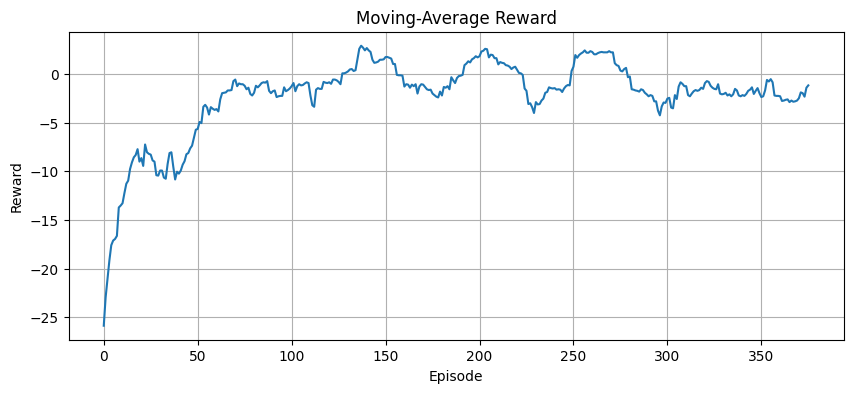

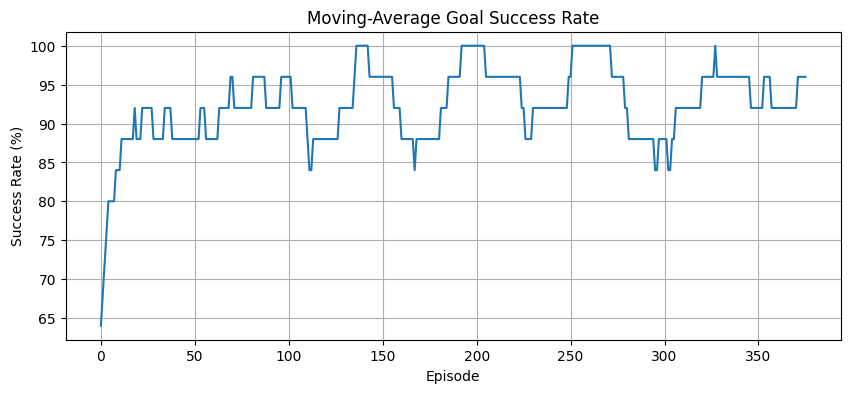

In [6]:
# Cell 7: Performance Visualization (LOCKED)
window = min(25, len(rewards_history))
reward_smooth = np.convolve(rewards_history, np.ones(window)/window, mode="valid")
success_smooth = np.convolve(success_history, np.ones(window)/window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(reward_smooth)
plt.title("Moving-Average Reward")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(100 * success_smooth)
plt.title("Moving-Average Goal Success Rate")
plt.xlabel("Episode")
plt.ylabel("Success Rate (%)")
plt.grid(True)
plt.show()
